# NOAA Tides & Currents - 조위(water level) 시계열 실습

> **학습목표**
>
- NOAA 공개 API에서 **서비스키 없이** 조위 데이터를 직접 수집한다.
- 6분 간격 시계열을 시간 단위와 일 단위로 재구성해 패턴을 읽는다.
- STL, ACF, PACF로 주기 구조를 진단한다.
- Seasonal Naive, AutoReg, SARIMA의 예측 성능을 비교한다.


## 0) 데이터 설명: NOAA Tides & Currents
- 출처: NOAA Tides & Currents API
- 엔드포인트: `https://api.tidesandcurrents.noaa.gov/api/prod/datagetter`
- 제품(product): `water_level`
- 관측소(station): `9414290` (San Francisco)
- 기간: `2025-01-01` ~ `2025-03-20`
- 시간대: `gmt`
- 기준면(datum): `MLLW`
- 단위: `metric` (meter)
- 인증: 불필요

## 실행 안내
1. 위에서 아래로 순서대로 실행한다.
2. NOAA API 호출이 있으므로 인터넷 연결이 필요하다.
3. 핵심 결과는 `result_6min`, `result_table`, `rolling_6min_summary`, `rolling_hourly_summary`에서 확인한다.

In [1]:
import importlib.util
import subprocess
import sys

required = {
    'requests': 'requests',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'statsmodels': 'statsmodels',
    'sklearn': 'scikit-learn',
}
missing = [pip_name for module_name, pip_name in required.items() if importlib.util.find_spec(module_name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

In [2]:
import warnings
warnings.filterwarnings('ignore')

import math
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = (12, 4)


## 1) API 설정
- 쿼리스트링으로 제품, 관측소, 날짜 구간, 시간대, 단위를 지정한다.


In [3]:
BASE_URL = 'https://api.tidesandcurrents.noaa.gov/api/prod/datagetter'

STATION = {
    'id': '9414290',
    'name': 'San Francisco',
}

BEGIN_DATE = '20250101'
END_DATE = '20250320'
PRODUCT = 'water_level'
DATUM = 'MLLW'
TIME_ZONE = 'gmt'
UNITS = 'metric'
FMT = 'json'
REQUEST_CHUNK_DAYS = 30

# 시각화와 진단 범위를 변수로 분리한다.
POINTS_PER_HOUR = 10
ZOOM_DAYS = 3
ACF_CYCLES = 4
PACF_LAGS = 60

STATION

{'id': '9414290', 'name': 'San Francisco'}

In [4]:
def _iter_date_chunks(begin_date: str, end_date: str, chunk_days: int = REQUEST_CHUNK_DAYS):
    start = pd.to_datetime(begin_date, format='%Y%m%d')
    end = pd.to_datetime(end_date, format='%Y%m%d')
    cursor = start

    while cursor <= end:
        chunk_end = min(cursor + pd.Timedelta(days=chunk_days - 1), end)
        yield cursor.strftime('%Y%m%d'), chunk_end.strftime('%Y%m%d')
        cursor = chunk_end + pd.Timedelta(days=1)


def fetch_noaa_water_level(station_id: str,
                           begin_date: str,
                           end_date: str,
                           product: str = PRODUCT,
                           datum: str = DATUM,
                           time_zone: str = TIME_ZONE,
                           units: str = UNITS,
                           fmt: str = FMT,
                           chunk_days: int = REQUEST_CHUNK_DAYS) -> tuple[pd.DataFrame, dict]:
    frames = []
    metadata = {}

    for chunk_begin, chunk_end in _iter_date_chunks(begin_date, end_date, chunk_days):
        params = {
            'product': product,
            'application': 'TimeSeriesAnalysis',
            'begin_date': chunk_begin,
            'end_date': chunk_end,
            'station': station_id,
            'datum': datum,
            'time_zone': time_zone,
            'units': units,
            'format': fmt,
        }

        r = requests.get(BASE_URL, params=params, timeout=30)
        r.raise_for_status()
        js = r.json()

        if 'data' not in js:
            raise ValueError(f'API 응답에 data가 없습니다: {js}')

        if not metadata:
            metadata = js.get('metadata', {})
        frames.append(pd.DataFrame(js['data']))

    if not frames:
        raise ValueError('수집된 데이터가 없습니다.')

    df = pd.concat(frames, ignore_index=True)
    df['t'] = pd.to_datetime(df['t'], errors='coerce')
    df['water_level_m'] = pd.to_numeric(df['v'], errors='coerce').astype('float32')
    df['sigma_m'] = pd.to_numeric(df['s'], errors='coerce').astype('float32')
    df = df[['t', 'water_level_m', 'sigma_m']].dropna(subset=['t', 'water_level_m'])
    df = df.set_index('t').sort_index()
    df = df[~df.index.duplicated(keep='last')]
    return df, metadata

## 2) 데이터 수집 및 구조 점검
- 행 수, 기간, 관측소 메타데이터를 확인한다.
- 이후 6분 간격으로 빈도를 고정한다.


In [5]:
df, meta = fetch_noaa_water_level(STATION['id'], BEGIN_DATE, END_DATE)

print('station :', meta.get('name'), meta.get('id'))
print('lat/lon :', meta.get('lat'), meta.get('lon'))
print('rows    :', len(df))
print('period  :', df.index.min(), '->', df.index.max())

df.head()


station : San Francisco 9414290
lat/lon : 37.8063 -122.4659
rows    : 18960
period  : 2025-01-01 00:00:00 -> 2025-03-20 23:54:00


,water_level_m,sigma_m
t,,
2025-01-01 00:00:00,0.035,0.052
2025-01-01 00:06:00,-0.012,0.060
2025-01-01 00:12:00,-0.051,0.058
2025-01-01 00:18:00,-0.087,0.059
2025-01-01 00:24:00,-0.119,0.050


In [6]:
# 원시 인덱스를 6분 간격으로 고정한다.
# 반일주조 패턴을 반영하기 위해 약 12.4시간을 한 주기로 둔다.
period = 124  # 6분 x 124 = 약 12.4시간

y_raw = df['water_level_m'].asfreq('6min')
missing_before = int(y_raw.isna().sum())

# 결측은 선형 보간으로 채워 진단과 예측에 사용할 단일 시계열을 만든다.
y = y_raw.interpolate(limit_direction='both').astype('float32')

# 시각화를 위해 시간 평균, 일별 요약 통계를 별도로 만든다.
hourly = y.resample('1h').mean().astype('float32')
daily = y.resample('1D').agg(['mean', 'min', 'max']).astype('float32')

summary = pd.DataFrame({
    'value': [
        len(df),
        len(y),
        missing_before,
        round(float(y.min()), 3),
        round(float(y.max()), 3),
        round(float(y.mean()), 3),
        period,
    ]
}, index=[
    'raw_rows',
    'regularized_rows',
    'missing_before_interpolation',
    'water_level_min_m',
    'water_level_max_m',
    'water_level_mean_m',
    'seasonal_period_steps',
])

summary


,value
raw_rows,18960.000
regularized_rows,18960.000
missing_before_interpolation,0.000
water_level_min_m,-0.427
water_level_max_m,2.101
water_level_mean_m,0.983
seasonal_period_steps,124.000


## 3) 데이터 정합성 검증
- 중복 인덱스, 간격 불일치, 결측 비율을 확인한다.
- 월별 결측률을 시각화해 데이터 공백 여부를 점검한다.

In [7]:
expected_delta = pd.Timedelta(minutes=6)
intervals = df.index.to_series().diff().dropna()
missing_mask = y_raw.isna()

if missing_mask.any():
    groups = (missing_mask != missing_mask.shift()).cumsum()
    max_gap_steps = int(missing_mask.groupby(groups).sum().max())
else:
    max_gap_steps = 0

validation_report = pd.DataFrame({
    'value': [
        int(df.index.duplicated().sum()),
        int((intervals != expected_delta).sum()),
        int(missing_mask.sum()),
        round(float(missing_mask.mean() * 100), 3),
        max_gap_steps,
        round(max_gap_steps * 6 / 60, 2),
    ]
}, index=[
    'duplicate_index_count',
    'non_6min_interval_count',
    'missing_count',
    'missing_ratio_pct',
    'max_missing_gap_steps',
    'max_missing_gap_hours',
])

validation_report

,value
duplicate_index_count,0.0
non_6min_interval_count,0.0
missing_count,0.0
missing_ratio_pct,0.0
max_missing_gap_steps,0.0
max_missing_gap_hours,0.0


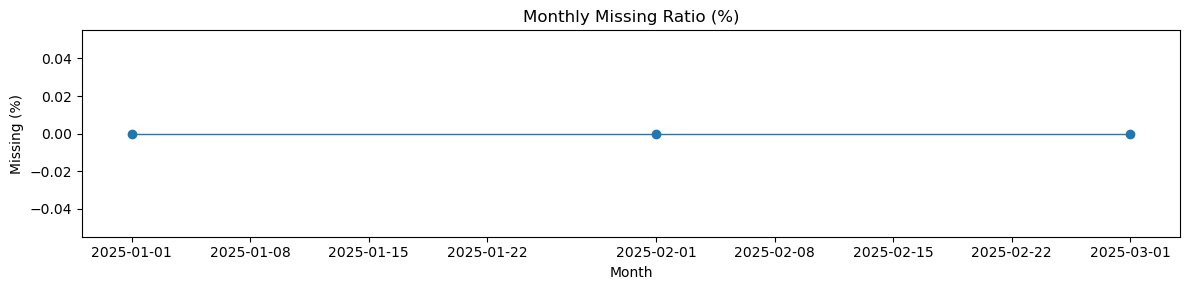

In [8]:
monthly_missing = (missing_mask.resample('MS').mean() * 100).astype('float32')

plt.figure(figsize=(12, 3))
plt.plot(monthly_missing.index, monthly_missing.values, marker='o', linewidth=1)
plt.title('Monthly Missing Ratio (%)')
plt.xlabel('Month')
plt.ylabel('Missing (%)')
plt.tight_layout()
plt.show()
plt.close('all')

## 4) 시각화
- 전체 시계열, 최근 3일 확대, 시간 평균, 일별 요약, 평균 조석 사이클을 확인한다.


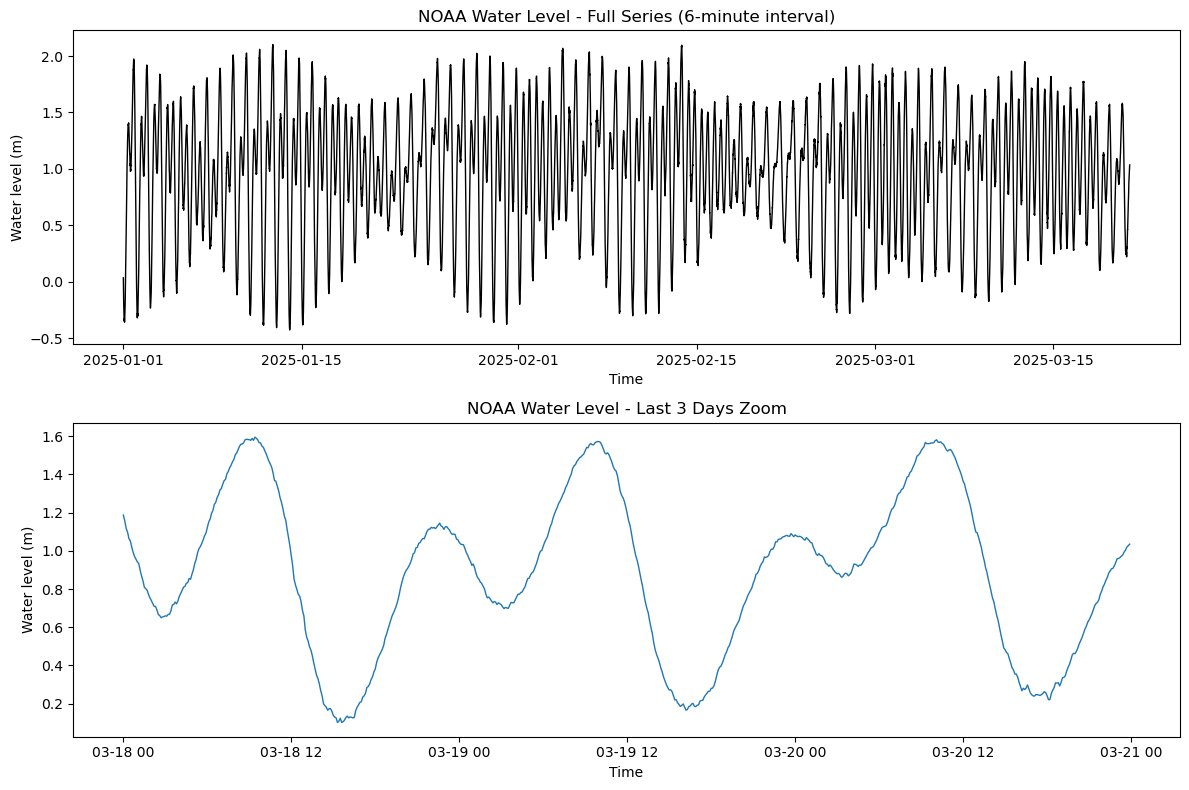

In [9]:
# 전체 구간과 최근 구간을 함께 그린다.
zoom_points = 24 * POINTS_PER_HOUR * ZOOM_DAYS
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

axes[0].plot(y.index, y, color='black', linewidth=1)
axes[0].set_title('NOAA Water Level - Full Series (6-minute interval)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Water level (m)')

axes[1].plot(y.index[-zoom_points:], y.iloc[-zoom_points:], color='tab:blue', linewidth=1)
axes[1].set_title('NOAA Water Level - Last 3 Days Zoom')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Water level (m)')

plt.tight_layout()
plt.show()
plt.close('all')


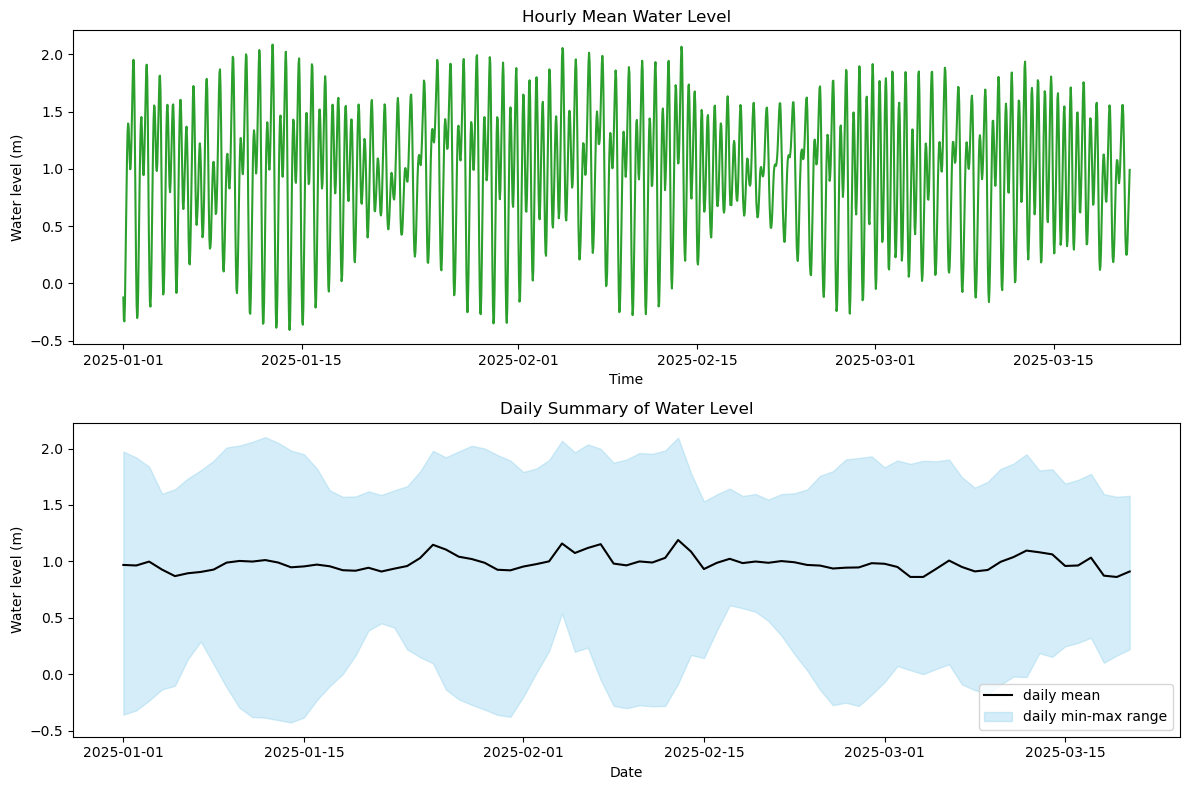

In [10]:
# 시간 평균은 고빈도 변동을 완화하고, 일별 min-max 범위는 하루 변동 폭을 보여준다.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

axes[0].plot(hourly.index, hourly, color='tab:green')
axes[0].set_title('Hourly Mean Water Level')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Water level (m)')

axes[1].plot(daily.index, daily['mean'], label='daily mean', color='black')
axes[1].fill_between(daily.index, daily['min'], daily['max'], color='skyblue', alpha=0.35, label='daily min-max range')
axes[1].set_title('Daily Summary of Water Level')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Water level (m)')
axes[1].legend()

plt.tight_layout()
plt.show()
plt.close('all')


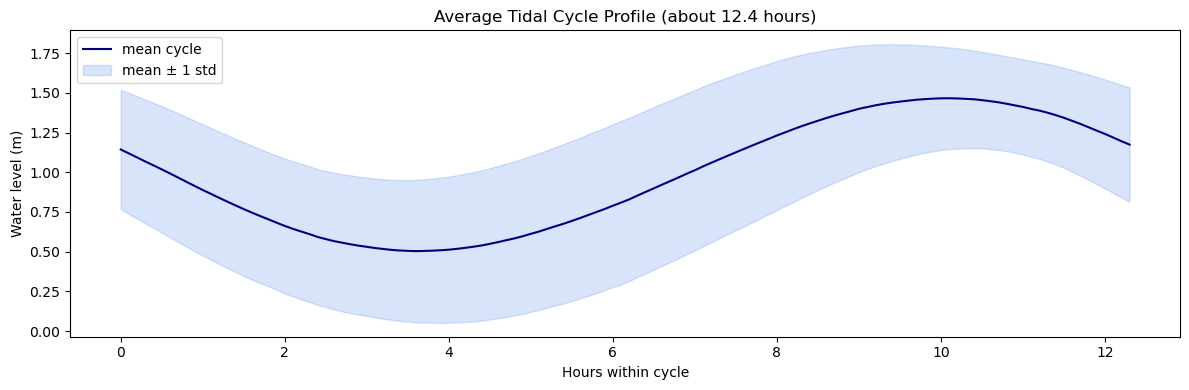

In [11]:
# 평균 조석 패턴을 보기 위해 주기 위치별 평균과 표준편차를 계산한다.
cycle_df = pd.DataFrame({
    'water_level_m': y.values,
    'cycle_step': np.arange(len(y)) % period,
})
cycle_profile = cycle_df.groupby('cycle_step')['water_level_m'].agg(['mean', 'std'])
cycle_hours = cycle_profile.index * 6 / 60

plt.figure(figsize=(12, 4))
plt.plot(cycle_hours, cycle_profile['mean'], color='navy', label='mean cycle')
plt.fill_between(
    cycle_hours,
    cycle_profile['mean'] - cycle_profile['std'],
    cycle_profile['mean'] + cycle_profile['std'],
    color='cornflowerblue',
    alpha=0.25,
    label='mean ± 1 std',
)
plt.title('Average Tidal Cycle Profile (about 12.4 hours)')
plt.xlabel('Hours within cycle')
plt.ylabel('Water level (m)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close('all')


## 5) STL / ACF / PACF 진단
- STL로 추세, 계절, 잔차를 분리한다.
- ACF와 PACF로 자기상관 구조를 확인한다.


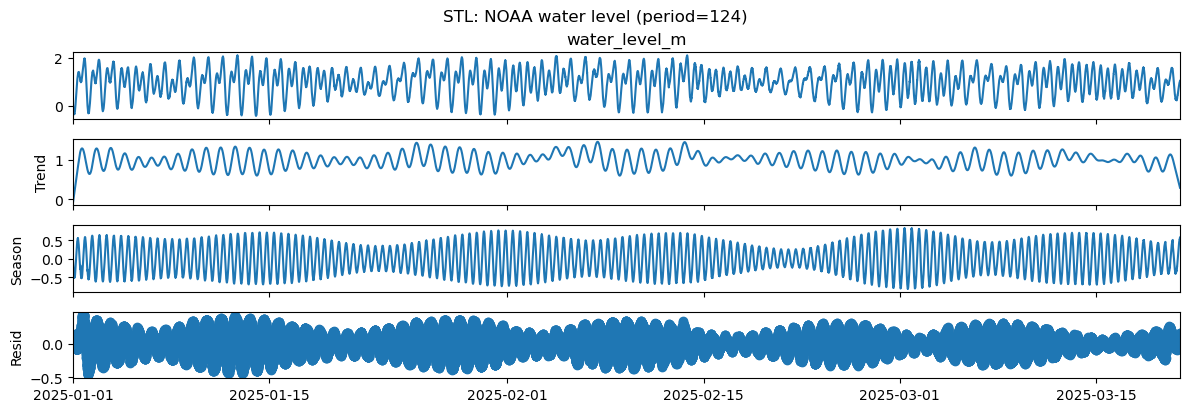

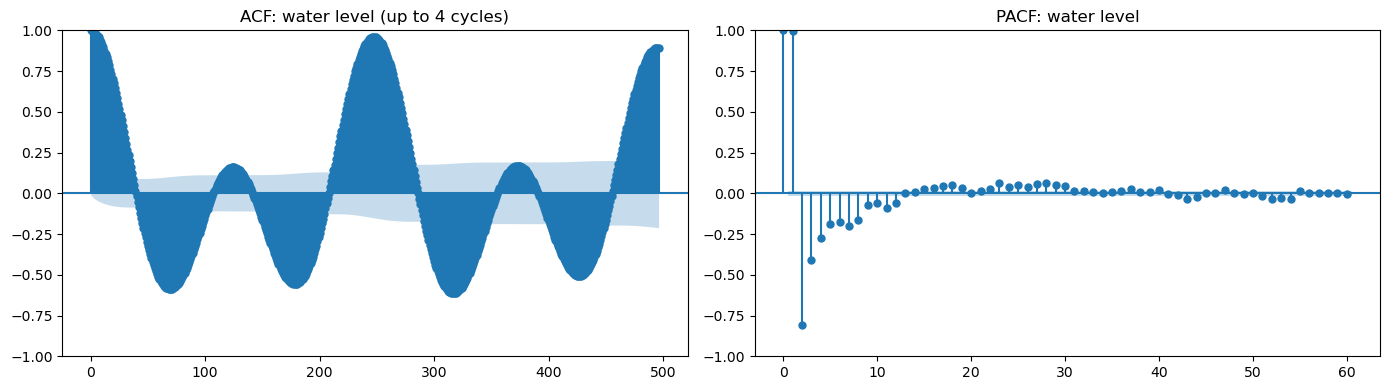

In [12]:
# STL은 설정한 주기(period=124)를 기준으로 반복 성분을 분리한다.
stl = STL(y, period=period, robust=True)
res = stl.fit()
res.plot()
plt.suptitle('STL: NOAA water level (period=124)', y=1.02)
plt.show()
plt.close('all')

# ACF는 주기 반복, PACF는 직접적인 자기상관을 확인하는 용도다.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=period * ACF_CYCLES, ax=axes[0])
axes[0].set_title('ACF: water level (up to 4 cycles)')
plot_pacf(y, lags=PACF_LAGS, ax=axes[1], method='ywm')
axes[1].set_title('PACF: water level')
plt.tight_layout()
plt.show()
plt.close('all')


## 6) 6분 시계열 예측 비교
- Seasonal Naive와 AutoReg를 같은 테스트 구간과 롤링 백테스트에서 비교한다.

In [13]:
h = period
test_n = period * 2

y_train = y.iloc[:-test_n]
y_test = y.iloc[-test_n:]

# Seasonal Naive
y_pred = pd.Series(index=y_test.index, dtype=float)
for t in y_test.index:
    t_lag = t - pd.Timedelta(minutes=6 * h)
    if t_lag in y.index:
        y_pred.loc[t] = y.loc[t_lag]

# AutoReg (6-min)
ar6_model = AutoReg(y_train, lags=496, old_names=False, seasonal=False).fit()
ar6_pred = ar6_model.predict(start=len(y_train), end=len(y_train) + test_n - 1, dynamic=False)
ar6_pred.index = y_test.index

rmse = math.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
rmse_ar6 = math.sqrt(mean_squared_error(y_test, ar6_pred))
mae_ar6 = mean_absolute_error(y_test, ar6_pred)

result_6min = pd.DataFrame([
    {'Model': 'Seasonal Naive (6min)', 'RMSE': rmse, 'MAE': mae},
    {'Model': 'AutoReg lags=496 (6min)', 'RMSE': rmse_ar6, 'MAE': mae_ar6},
]).sort_values('RMSE')
result_6min

,Model,RMSE,MAE
1,AutoReg lags=496 (6min),0.055387,0.048586
0,Seasonal Naive (6min),0.627593,0.574121


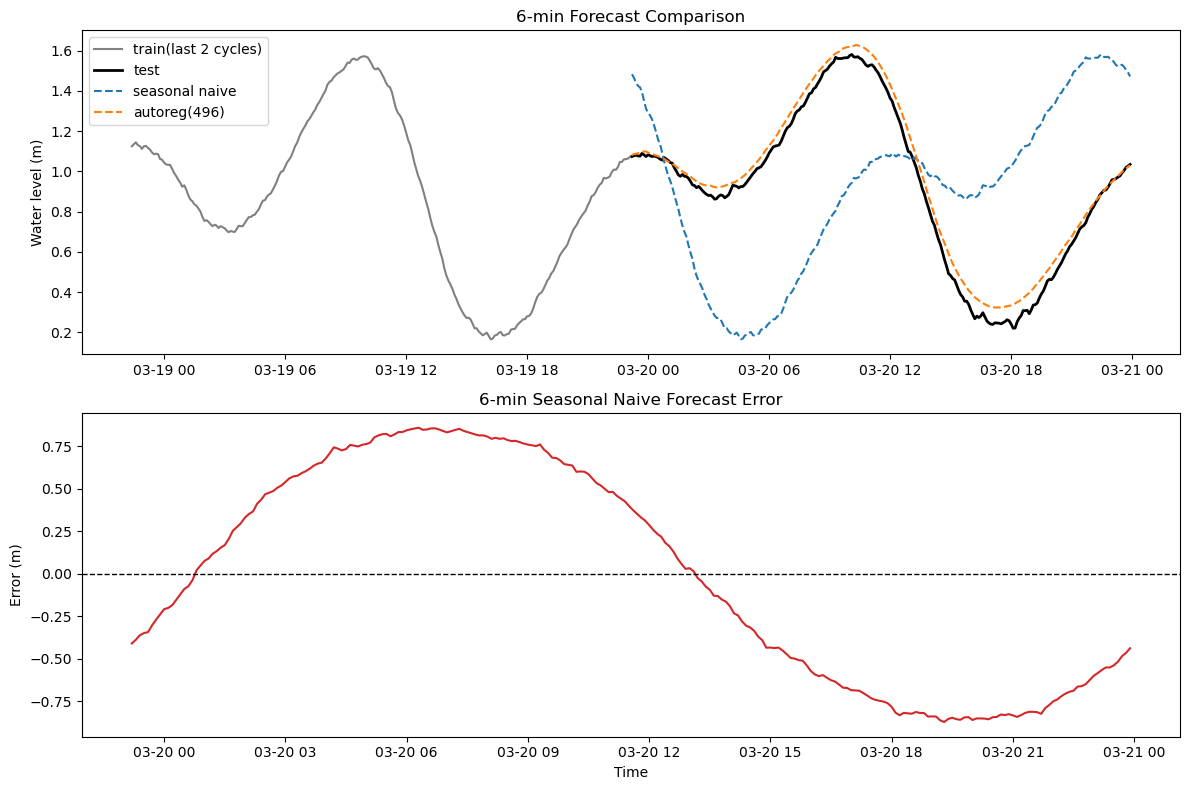

In [14]:
# 예측 구간과 오차 시계열을 함께 그린다.
forecast_error = y_test - y_pred

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)

axes[0].plot(y_train.index[-period * 2:], y_train.iloc[-period * 2:], label='train(last 2 cycles)', color='gray')
axes[0].plot(y_test.index, y_test, label='test', color='black', linewidth=2)
axes[0].plot(y_pred.index, y_pred, label='seasonal naive', linestyle='--')
axes[0].plot(ar6_pred.index, ar6_pred, label='autoreg(496)', linestyle='--')
axes[0].set_title('6-min Forecast Comparison')
axes[0].set_ylabel('Water level (m)')
axes[0].legend()

axes[1].plot(forecast_error.index, forecast_error, color='tab:red')
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].set_title('6-min Seasonal Naive Forecast Error')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Error (m)')

plt.tight_layout()
plt.show()
plt.close('all')

In [15]:
# 6분 시계열 롤링 백테스트(2주기 예측, 2주기 간격 이동)
rolling_6min_window = period * 2
rolling_6min_step = period * 2
rolling_6min_start = max(rolling_6min_window * 6, 3000)

records = []
for split in range(rolling_6min_start, len(y) - rolling_6min_window + 1, rolling_6min_step):
    tr = y.iloc[:split]
    te = y.iloc[split:split + rolling_6min_window]

    naive = pd.Series(index=te.index, dtype=float)
    for t in te.index:
        t_lag = t - pd.Timedelta(minutes=6 * period)
        if t_lag in y.index:
            naive.loc[t] = y.loc[t_lag]

    ar = AutoReg(tr, lags=496, old_names=False, seasonal=False).fit()
    ar_pred = ar.predict(start=len(tr), end=len(tr) + rolling_6min_window - 1, dynamic=False)
    ar_pred.index = te.index

    records.append({
        'split_end': te.index.max(),
        'naive_rmse': math.sqrt(mean_squared_error(te, naive)),
        'autoreg_rmse': math.sqrt(mean_squared_error(te, ar_pred)),
        'naive_mae': mean_absolute_error(te, naive),
        'autoreg_mae': mean_absolute_error(te, ar_pred),
    })

rolling_6min_df = pd.DataFrame(records)
rolling_6min_summary = pd.DataFrame({
    'Model': ['Seasonal Naive (6min)', 'AutoReg lags=496 (6min)'],
    'RMSE_mean': [rolling_6min_df['naive_rmse'].mean(), rolling_6min_df['autoreg_rmse'].mean()],
    'MAE_mean': [rolling_6min_df['naive_mae'].mean(), rolling_6min_df['autoreg_mae'].mean()],
}).sort_values('RMSE_mean')

rolling_6min_summary

,Model,RMSE_mean,MAE_mean
1,AutoReg lags=496 (6min),0.066385,0.055682
0,Seasonal Naive (6min),0.627472,0.571426


## 7) 추가 모델 비교: 시간 평균 시계열
- 6분 간격 원시 시계열은 계절 주기(`124`)가 길어 모수 모델 비교가 다소 무겁다.
- 모델 비교는 `1시간 평균 시계열`로 변환한 뒤 수행한다.
- 시간 평균 시계열에서는 단일 테스트 구간과 롤링 백테스트를 함께 확인한다.

In [16]:
# 모델 비교는 시간 평균 시계열에서 수행한다.
# 1시간 평균으로 변환하면 약 12시간 주기를 계절 주기로 둘 수 있다.
hourly_y = hourly.copy()
hourly_period = 12
hourly_test_n = hourly_period * 4  # 마지막 48시간 테스트

hourly_train = hourly_y.iloc[:-hourly_test_n]
hourly_test = hourly_y.iloc[-hourly_test_n:]

def eval_forecast(y_true, y_pred):
    return {
        'RMSE': math.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred),
    }

print('train rows:', len(hourly_train))
print('test rows :', len(hourly_test))


train rows: 1848
test rows : 48


In [17]:
# 1) Seasonal Naive: 12시간 전 값을 그대로 복사한다.
hourly_naive = pd.Series(index=hourly_test.index, dtype=float)
for t in hourly_test.index:
    t_lag = t - pd.Timedelta(hours=hourly_period)
    if t_lag in hourly_y.index:
        hourly_naive.loc[t] = hourly_y.loc[t_lag]

# 2) AutoReg: 최근 시차 정보를 이용해 다음 값을 예측한다.
autoreg_model = AutoReg(hourly_train, lags=96, old_names=False, seasonal=False).fit()
hourly_autoreg = autoreg_model.predict(
    start=len(hourly_train),
    end=len(hourly_train) + hourly_test_n - 1,
    dynamic=False,
)
hourly_autoreg.index = hourly_test.index

# 3) SARIMA: 자기회귀와 계절 성분을 함께 반영한다.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sarima_model = SARIMAX(
        hourly_train,
        order=(2, 0, 1),
        seasonal_order=(1, 0, 0, hourly_period),
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=200)

hourly_sarima = sarima_model.forecast(hourly_test_n)
hourly_sarima.index = hourly_test.index

result_table = pd.DataFrame([
    {'Model': 'Seasonal Naive (hourly)', **eval_forecast(hourly_test, hourly_naive)},
    {'Model': 'AutoReg lags=96', **eval_forecast(hourly_test, hourly_autoreg)},
    {'Model': 'SARIMA (2,0,1)x(1,0,0,12)', **eval_forecast(hourly_test, hourly_sarima)},
]).sort_values('RMSE')

result_table

,Model,RMSE,MAE
1,AutoReg lags=96,0.041327,0.033534
2,"SARIMA (2,0,1)x(1,0,0,12)",0.329339,0.250568
0,Seasonal Naive (hourly),0.586527,0.538971


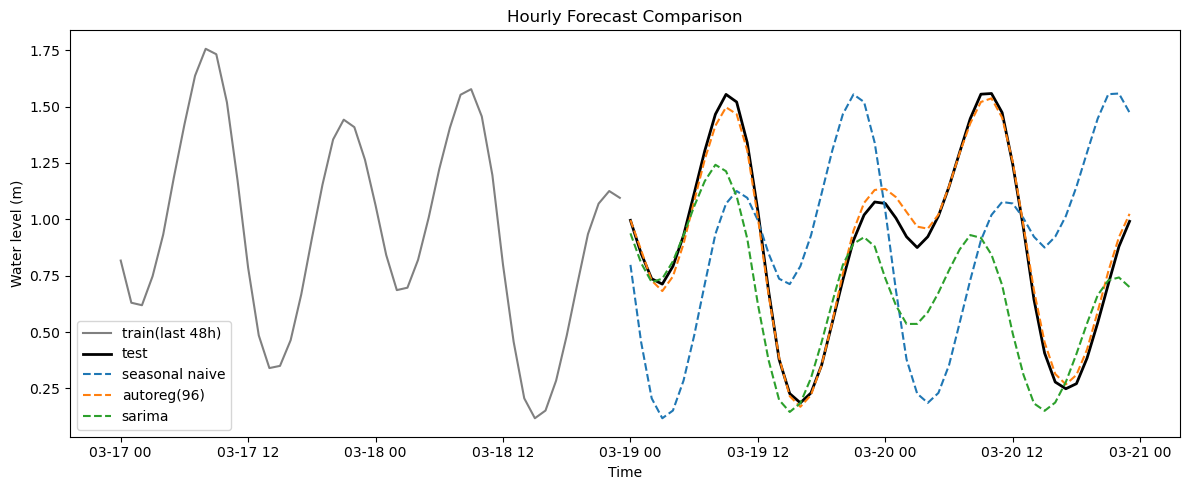

In [18]:
# 비교 구간은 마지막 48시간으로 고정한다.
plt.figure(figsize=(12, 5))
plt.plot(hourly_train.index[-48:], hourly_train.iloc[-48:], label='train(last 48h)', color='gray')
plt.plot(hourly_test.index, hourly_test, label='test', color='black', linewidth=2)
plt.plot(hourly_naive.index, hourly_naive, label='seasonal naive', linestyle='--')
plt.plot(hourly_autoreg.index, hourly_autoreg, label='autoreg(96)', linestyle='--')
plt.plot(hourly_sarima.index, hourly_sarima, label='sarima', linestyle='--')
plt.title('Hourly Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Water level (m)')
plt.legend()
plt.tight_layout()
plt.show()
plt.close('all')

In [19]:
# 시간 평균 시계열 롤링 백테스트(48시간 예측, 12시간 간격 이동)
rolling_window = 48
rolling_step = 12
start_idx = max(rolling_window * 3, 200)

records = []
for split in range(start_idx, len(hourly_y) - rolling_window + 1, rolling_step):
    tr = hourly_y.iloc[:split]
    te = hourly_y.iloc[split:split + rolling_window]

    naive = pd.Series(index=te.index, dtype=float)
    for t in te.index:
        t_lag = t - pd.Timedelta(hours=hourly_period)
        if t_lag in hourly_y.index:
            naive.loc[t] = hourly_y.loc[t_lag]

    ar = AutoReg(tr, lags=96, old_names=False, seasonal=False).fit()
    ar_pred = ar.predict(start=len(tr), end=len(tr) + rolling_window - 1, dynamic=False)
    ar_pred.index = te.index

    records.append({
        'split_end': te.index.max(),
        'naive_rmse': math.sqrt(mean_squared_error(te, naive)),
        'autoreg_rmse': math.sqrt(mean_squared_error(te, ar_pred)),
        'naive_mae': mean_absolute_error(te, naive),
        'autoreg_mae': mean_absolute_error(te, ar_pred),
    })

rolling_hourly_df = pd.DataFrame(records)
rolling_hourly_summary = pd.DataFrame({
    'Model': ['Seasonal Naive (hourly)', 'AutoReg lags=96'],
    'RMSE_mean': [rolling_hourly_df['naive_rmse'].mean(), rolling_hourly_df['autoreg_rmse'].mean()],
    'MAE_mean': [rolling_hourly_df['naive_mae'].mean(), rolling_hourly_df['autoreg_mae'].mean()],
}).sort_values('RMSE_mean')

rolling_hourly_summary

,Model,RMSE_mean,MAE_mean
1,AutoReg lags=96,0.082869,0.067560
0,Seasonal Naive (hourly),0.654346,0.592529


## 8) 요약
1. NOAA 공개 API에서 조위 데이터를 직접 수집했다.
2. 중복/간격/결측 기준으로 데이터 정합성을 검증했다.
3. 6분 간격 시계열을 시각화하고, 시간 평균과 일별 요약으로 패턴을 정리했다.
4. STL / ACF / PACF로 반복 구조를 확인했다.
5. 6분 시계열에서는 Seasonal Naive / AutoReg(496)를 비교했고, 롤링 백테스트에서도 AutoReg(496)가 더 낮은 평균 오차를 보였다.
6. 시간 평균 시계열에서는 Seasonal Naive / AutoReg(96) / SARIMA를 비교했고, 롤링 백테스트에서도 AutoReg(96)가 더 낮은 평균 오차를 보였다.
7. 최종 추천 모델은 시간 평균 시계열의 `AutoReg(96)`이다.